# **Práctica 5**

## **Resumen**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq


**4.1)** Cree una señal que sea la suma de tres componentes sinusoidales con frecuencias de 40, 
80 y 160 Hz. Defina la frecuencia de muestreo mínima necesaria para representar la señal, 
y utilice la frecuencia de muestreo necesaria para representarla apropiadamente.

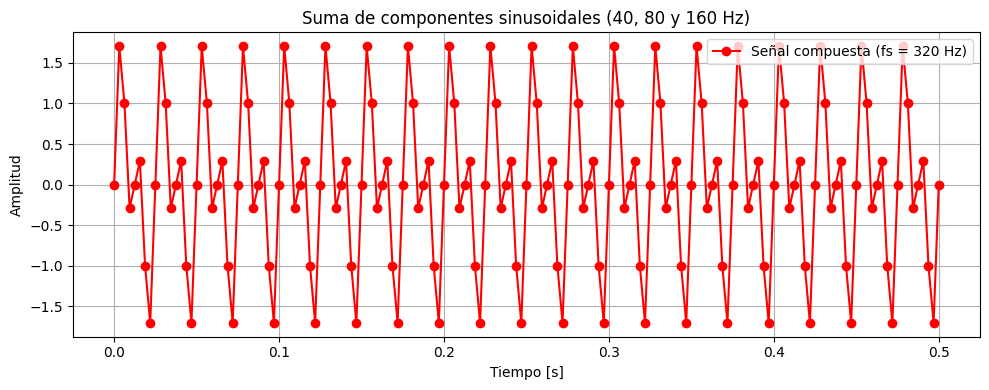

In [2]:
ts = 1/320
t = np.arange(0,0.5+ts,ts)
signal = (np.sin(2*np.pi*40*t)) + (np.sin(2*np.pi*80*t)) + (np.sin(2*np.pi*160*t))


plt.figure(figsize=(10, 4))
plt.plot(t, signal, label="Señal compuesta (fs = 320 Hz)", color= 'red', marker='o')
plt.title("Suma de componentes sinusoidales (40, 80 y 160 Hz)")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



**4.2)** Calcule  la  transformada  de  Fourier  de  la  señal  y  grafique  el  espectro  de  frecuencia. 
Identifique en el espectro las frecuencias que componen la señal (trabaje con 10 periodos 
de la señal)

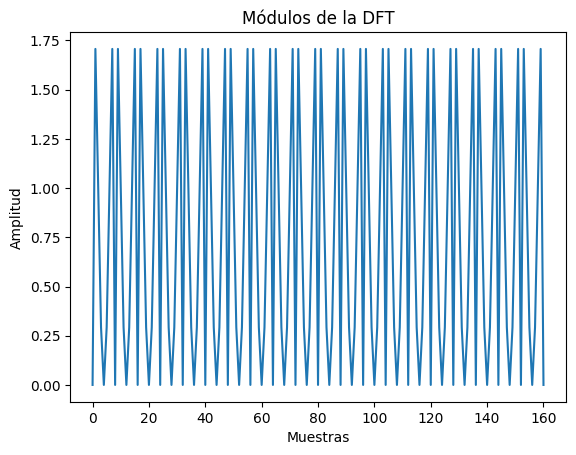

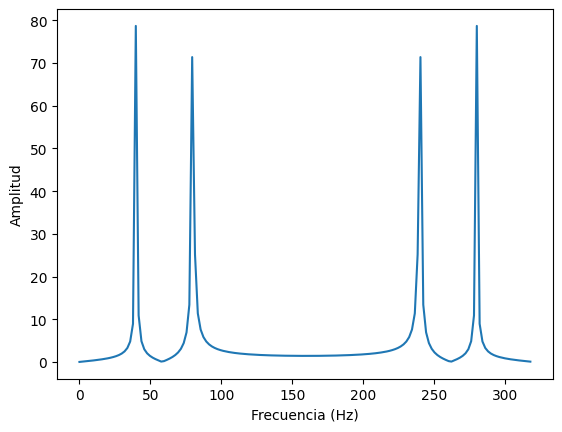

In [4]:
senal = np.fft.fft(signal) 

plt.plot(abs(signal)) 
plt.title('Módulos de la DFT') 
plt.xlabel('Muestras') 
plt.ylabel('Amplitud') 
plt.show()

Fs = 1/ts
N = len(senal) 
F = np.arange(0,N)*Fs/N 
plt.plot(F,abs(senal) )
plt.xlabel('Frecuencia (Hz)') 
plt.ylabel('Amplitud') 
plt.show()

**4.3)** Consulte la función que permite realizar el cálculo de la transformada inversa de Fourier. 
Aplíquelo a la señal anterior.

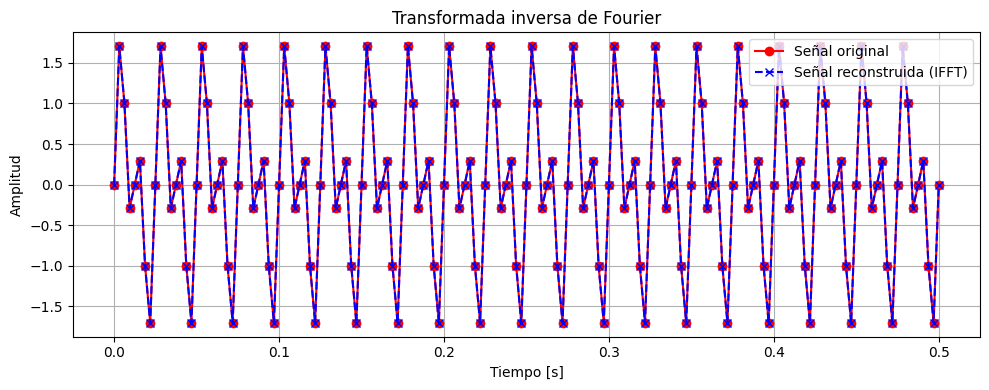

¿Reconstrucción correcta?: True
Parte imaginaria máxima: 4.5495798500239e-16


In [5]:
from scipy.fft import ifft   # equivalente: np.fft.ifft

# 'signal' contiene la FFT calculada en el punto 4.2
signal_rec = ifft(senal)

# Señal original para comparar (en 4.2 se sobrescribió la variable)
signal_orig = np.sin(2*np.pi*40*t) + np.sin(2*np.pi*80*t) + np.sin(2*np.pi*160*t)

plt.figure(figsize=(10, 4))
plt.plot(t, signal_orig, 'o-', color='red', label='Señal original')
plt.plot(t, signal_rec.real, 'x--', color='blue', label='Señal reconstruida (IFFT)')
plt.title('Transformada inversa de Fourier')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("¿Reconstrucción correcta?:", np.allclose(signal_orig, signal_rec.real))
print("Parte imaginaria máxima:", np.max(np.abs(signal_rec.imag)))

**4.4)**

Sí este código aplica un filtro **pasa banda ideal** que se aplica directamente en el dominio de la frecuencia.

Esto ocurre porque:

1. `F1 = np.fft.fft(x)` pasa la señal al dominio de la frecuencia.
2. `F2 = np.zeros(...)` crea un espectro vacío, todo en cero.
3. `F2[9:13] = F1[9:13]` copia solo los coeficientes `9` a `12` y deja el resto en cero. Equivale a multiplicar el espectro por una ventana rectangular $H[k]$, que vale $1$ en la banda elegida y $0$ fuera de ella:
   $$X_{\text{filtrada}}[k] = X[k] \cdot H[k]$$
4. `np.fft.ifft(F2)` devuelve la señal al tiempo. Lo que queda son solo las frecuencias de esa banda.

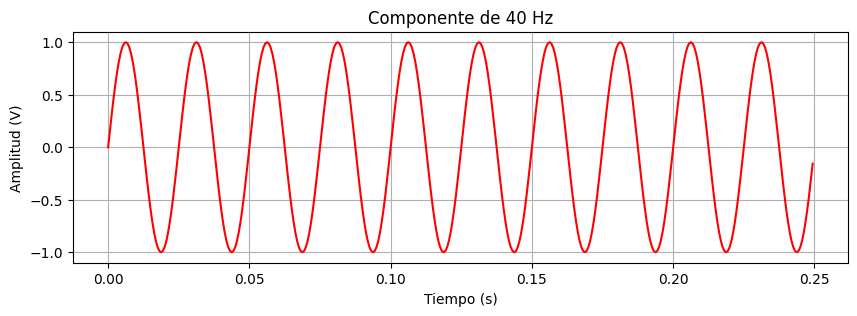

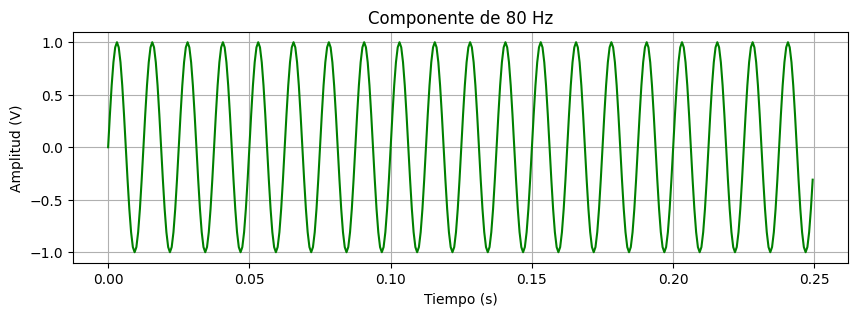

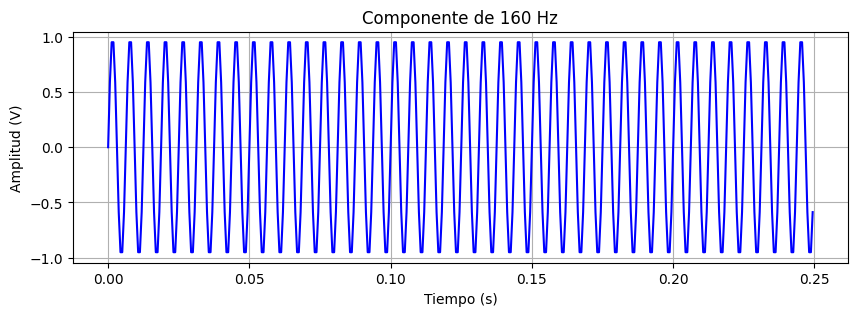

In [13]:
fs = 1600
ts = 1/fs
t = np.arange(0, 0.25, ts)      # 10 periodos, N = 400
x = np.sin(2*np.pi*40*t) + np.sin(2*np.pi*80*t) + np.sin(2*np.pi*160*t)

F1 = np.fft.fft(x)
N = len(F1)

# ----- Componente de 40 Hz -----
F2 = np.zeros(N, dtype=complex)
F2[9:12] = F1[9:12]             # alrededor del bin 10
F2[389:392] = F1[389:392]       # espejo (bin 390)
x40 = np.fft.ifft(F2)

plt.figure(figsize=(10, 3))
plt.plot(t, np.real(x40), color='red')
plt.title('Componente de 40 Hz')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.grid(True)
plt.show()

# ----- Componente de 80 Hz -----
F3 = np.zeros(N, dtype=complex)
F3[19:22] = F1[19:22]           # alrededor del bin 20
F3[379:382] = F1[379:382]       # espejo (bin 380)
x80 = np.fft.ifft(F3)

plt.figure(figsize=(10, 3))
plt.plot(t, np.real(x80), color='green')
plt.title('Componente de 80 Hz')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.grid(True)
plt.show()

# ----- Componente de 160 Hz -----
F4 = np.zeros(N, dtype=complex)
F4[39:42] = F1[39:42]           # alrededor del bin 40
F4[359:362] = F1[359:362]       # espejo (bin 360)
x160 = np.fft.ifft(F4)

plt.figure(figsize=(10, 3))
plt.plot(t, np.real(x160), color='blue')
plt.title('Componente de 160 Hz')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.grid(True)
plt.show()